In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from collections import Counter
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [3]:
def run(Xtr,ytr,Xte,yte,name,**kw):
    p = RandomForestClassifier(random_state=42,**kw).fit(Xtr,ytr).predict(Xte)
    print(f"{name:<24} Accuracy={accuracy_score(yte,p):.3f}  Macro-F1={f1_score(yte,p,average='macro'):.3f}")
    return p

mk = dict(n_samples=1000,n_features=6,n_informative=4,n_redundant=0,n_classes=3,n_clusters_per_class=1,random_state=42)

In [4]:
Xb,yb = make_classification(**mk)
print("Balanced:", Counter(yb))
a,b,c,d = train_test_split(Xb,yb,test_size=0.2,random_state=42,stratify=yb)
run(a,c,b,d,"Balanced data")

Balanced: Counter({np.int64(2): 335, np.int64(0): 335, np.int64(1): 330})
Balanced data            Accuracy=0.880  Macro-F1=0.881


array([1, 1, 0, 1, 1, 0, 2, 0, 1, 1, 0, 2, 0, 0, 2, 0, 0, 0, 2, 2, 1, 0,
       1, 1, 1, 2, 2, 0, 2, 0, 2, 2, 0, 1, 0, 1, 1, 1, 0, 2, 0, 1, 1, 2,
       0, 0, 1, 1, 0, 1, 1, 2, 2, 0, 1, 0, 2, 2, 0, 0, 1, 1, 1, 0, 2, 0,
       2, 1, 2, 2, 2, 1, 2, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2, 1, 0, 2, 1, 2,
       1, 2, 0, 1, 1, 2, 2, 1, 2, 0, 2, 1, 1, 1, 1, 2, 1, 0, 0, 0, 2, 2,
       0, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 0, 0, 0, 2, 2, 0, 0, 0,
       0, 1, 1, 1, 2, 1, 2, 2, 2, 1, 1, 0, 1, 2, 1, 0, 1, 0, 1, 1, 1, 0,
       0, 1, 2, 0, 0, 1, 2, 0, 2, 1, 0, 0, 2, 2, 2, 0, 1, 1, 1, 2, 1, 0,
       2, 0, 1, 1, 0, 0, 2, 0, 2, 1, 0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 0, 1,
       0, 1])

Imbalanced: Counter({np.int64(0): 844, np.int64(1): 100, np.int64(2): 56})


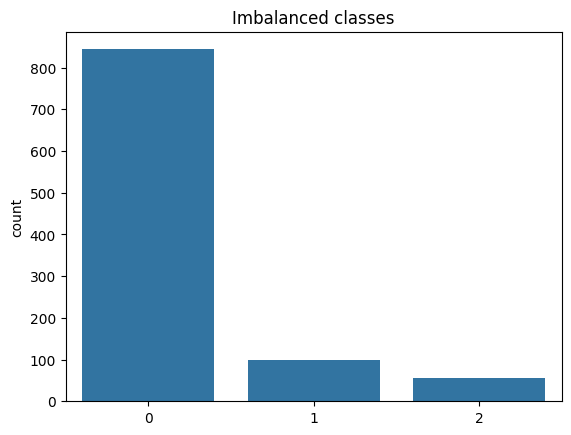

Imbalanced (baseline)    Accuracy=0.945  Macro-F1=0.777
[[169   0   0]
 [  4  16   0]
 [  4   3   4]]
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       169
           1       0.84      0.80      0.82        20
           2       1.00      0.36      0.53        11

    accuracy                           0.94       200
   macro avg       0.93      0.72      0.78       200
weighted avg       0.95      0.94      0.94       200



In [5]:
X,y = make_classification(weights=[0.85,0.10,0.05],**mk)
print("Imbalanced:", Counter(y)); sns.countplot(x=y); plt.title("Imbalanced classes"); plt.show()
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
p = run(Xtr,ytr,Xte,yte,"Imbalanced (baseline)")
print(confusion_matrix(yte,p)); print(classification_report(yte,p,zero_division=0))

In [6]:
Xo,yo = RandomOverSampler(random_state=42).fit_resample(Xtr,ytr);  run(Xo,yo,Xte,yte,"Random oversampling")
Xu,yu = RandomUnderSampler(random_state=42).fit_resample(Xtr,ytr); run(Xu,yu,Xte,yte,"Random undersampling")
Xs,ys = SMOTE(random_state=42).fit_resample(Xtr,ytr);              run(Xs,ys,Xte,yte,"SMOTE")
run(Xtr,ytr,Xte,yte,"class_weight=balanced",class_weight="balanced")

Random oversampling      Accuracy=0.950  Macro-F1=0.788
Random undersampling     Accuracy=0.805  Macro-F1=0.618
SMOTE                    Accuracy=0.925  Macro-F1=0.763
class_weight=balanced    Accuracy=0.925  Macro-F1=0.665


array([0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 1,
       0, 0])